## Video Game Sales Prediction

Data source: https://www.kaggle.com/datasets/gregorut/videogamesales

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import tensorflow as tf

from sklearn.metrics import r2_score

I0000 00:00:1794502149.722882    5938 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794502150.298996    5938 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794502152.902274    5938 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
data = pd.read_csv('archive/vgsales.csv', index_col='Rank')
data

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Rank,,,,,,,,,,
1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16598 entries, 1 to 16600
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Name          16598 non-null  object 
 1   Platform      16598 non-null  object 
 2   Year          16327 non-null  float64
 3   Genre         16598 non-null  object 
 4   Publisher     16540 non-null  object 
 5   NA_Sales      16598 non-null  float64
 6   EU_Sales      16598 non-null  float64
 7   JP_Sales      16598 non-null  float64
 8   Other_Sales   16598 non-null  float64
 9   Global_Sales  16598 non-null  float64
dtypes: float64(6), object(4)
memory usage: 1.4+ MB


### Preprocessing

In [6]:
columns_to_drop = ['Name', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

data = data.drop(columns_to_drop, axis=1)

In [7]:
data

,Platform,Year,Genre,Publisher,Global_Sales
Rank,,,,,
1,Wii,2006.0,Sports,Nintendo,82.74
2,NES,1985.0,Platform,Nintendo,40.24
3,Wii,2008.0,Racing,Nintendo,35.82
4,Wii,2009.0,Sports,Nintendo,33.00
5,GB,1996.0,Role-Playing,Nintendo,31.37
...,...,...,...,...,...
16596,GBA,2002.0,Platform,Kemco,0.01
16597,GC,2003.0,Shooter,Infogrames,0.01
16598,PS2,2008.0,Racing,Activision,0.01


In [8]:
data.isnull().sum()

Platform          0
Year            271
Genre             0
Publisher        58
Global_Sales      0
dtype: int64

In [9]:
data['Year'] = data['Year'].fillna(data['Year'].mean())

In [10]:
data.isnull().sum()

Platform         0
Year             0
Genre            0
Publisher       58
Global_Sales     0
dtype: int64

In [12]:
data = data.dropna(axis=0).reset_index(drop=True)
data

,Platform,Year,Genre,Publisher,Global_Sales
0,Wii,2006.0,Sports,Nintendo,82.74
1,NES,1985.0,Platform,Nintendo,40.24
2,Wii,2008.0,Racing,Nintendo,35.82
3,Wii,2009.0,Sports,Nintendo,33.00
4,GB,1996.0,Role-Playing,Nintendo,31.37
...,...,...,...,...,...
16535,GBA,2002.0,Platform,Kemco,0.01
16536,GC,2003.0,Shooter,Infogrames,0.01
16537,PS2,2008.0,Racing,Activision,0.01
16538,DS,2010.0,Puzzle,7G//AMES,0.01


In [13]:
data.isna().sum()

Platform        0
Year            0
Genre           0
Publisher       0
Global_Sales    0
dtype: int64

#### Encoding

In [14]:
data

,Platform,Year,Genre,Publisher,Global_Sales
0,Wii,2006.0,Sports,Nintendo,82.74
1,NES,1985.0,Platform,Nintendo,40.24
2,Wii,2008.0,Racing,Nintendo,35.82
3,Wii,2009.0,Sports,Nintendo,33.00
4,GB,1996.0,Role-Playing,Nintendo,31.37
...,...,...,...,...,...
16535,GBA,2002.0,Platform,Kemco,0.01
16536,GC,2003.0,Shooter,Infogrames,0.01
16537,PS2,2008.0,Racing,Activision,0.01
16538,DS,2010.0,Puzzle,7G//AMES,0.01


In [15]:
data['Platform'].unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       '3DS', 'PS4', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne', 'GC',
       'WiiU', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

In [16]:
data['Genre'].unique()

array(['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', 'Misc',
       'Shooter', 'Simulation', 'Action', 'Fighting', 'Adventure',
       'Strategy'], dtype=object)

In [19]:
counts = data['Publisher'].value_counts()
counts

Publisher
Electronic Arts                 1351
Activision                       975
Namco Bandai Games               932
Ubisoft                          921
Konami Digital Entertainment     832
                                ... 
Media Entertainment                1
New World Computing                1
Genterprise                        1
Rain Games                         1
UIG Entertainment                  1
Name: count, Length: 578, dtype: int64

In [20]:
counts['Genterprise']

np.int64(1)

In [22]:
data['Publisher'] = data['Publisher'].apply(lambda x: 'Small Publisher' if counts[x] < 50 else x)

In [23]:
data['Publisher'].value_counts()

Publisher
Small Publisher                           3342
Electronic Arts                           1351
Activision                                 975
Namco Bandai Games                         932
Ubisoft                                    921
Konami Digital Entertainment               832
THQ                                        715
Nintendo                                   703
Sony Computer Entertainment                683
Sega                                       639
Take-Two Interactive                       413
Capcom                                     381
Atari                                      363
Tecmo Koei                                 338
Square Enix                                233
Warner Bros. Interactive Entertainment     232
Disney Interactive Studios                 218
Unknown                                    203
Eidos Interactive                          198
Midway Games                               198
505 Games                                  192
Mic

In [24]:
data

,Platform,Year,Genre,Publisher,Global_Sales
0,Wii,2006.0,Sports,Nintendo,82.74
1,NES,1985.0,Platform,Nintendo,40.24
2,Wii,2008.0,Racing,Nintendo,35.82
3,Wii,2009.0,Sports,Nintendo,33.00
4,GB,1996.0,Role-Playing,Nintendo,31.37
...,...,...,...,...,...
16535,GBA,2002.0,Platform,Small Publisher,0.01
16536,GC,2003.0,Shooter,Infogrames,0.01
16537,PS2,2008.0,Racing,Activision,0.01
16538,DS,2010.0,Puzzle,Small Publisher,0.01


In [25]:
onehot_columns = ['Platform', 'Genre', 'Publisher']
onehot_prefixes = ['PL', 'G', 'PU']

In [26]:
# nominal encoding
def onehot_encode(df, columns, prefixes):
    df = df.copy()
    for column, prefix in zip(columns, prefixes):
        dummies = pd.get_dummies(df[column], prefix=prefix, dtype=int)
        df = pd.concat([df, dummies], axis=1)
        df = df.drop(column, axis=1)
    return df

In [27]:
data = onehot_encode(data, onehot_columns, onehot_prefixes)

In [28]:
data

,Year,Global_Sales,PL_2600,PL_3DO,PL_3DS,PL_DC,PL_DS,PL_GB,PL_GBA,PL_GC,...,PU_SquareSoft,PU_THQ,PU_Take-Two Interactive,PU_Tecmo Koei,PU_Ubisoft,PU_Unknown,PU_Virgin Interactive,PU_Vivendi Games,PU_Warner Bros. Interactive Entertainment,PU_Zoo Digital Publishing
0,2006.0,82.74,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1985.0,40.24,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2008.0,35.82,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2009.0,33.00,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1996.0,31.37,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16535,2002.0,0.01,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
16536,2003.0,0.01,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
16537,2008.0,0.01,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16538,2010.0,0.01,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### Splitting and Scaling

In [29]:
y = data['Global_Sales'].copy()
X = data.drop('Global_Sales', axis=1).copy()

In [30]:
y

0        82.74
1        40.24
2        35.82
3        33.00
4        31.37
         ...  
16535     0.01
16536     0.01
16537     0.01
16538     0.01
16539     0.01
Name: Global_Sales, Length: 16540, dtype: float64

In [31]:
X

,Year,PL_2600,PL_3DO,PL_3DS,PL_DC,PL_DS,PL_GB,PL_GBA,PL_GC,PL_GEN,...,PU_SquareSoft,PU_THQ,PU_Take-Two Interactive,PU_Tecmo Koei,PU_Ubisoft,PU_Unknown,PU_Virgin Interactive,PU_Vivendi Games,PU_Warner Bros. Interactive Entertainment,PU_Zoo Digital Publishing
0,2006.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1985.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2008.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2009.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1996.0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16535,2002.0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
16536,2003.0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
16537,2008.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16538,2010.0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [32]:
scaler = StandardScaler()

X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

In [33]:
X

,Year,PL_2600,PL_3DO,PL_3DS,PL_DC,PL_DS,PL_GB,PL_GBA,PL_GC,PL_GEN,...,PU_SquareSoft,PU_THQ,PU_Take-Two Interactive,PU_Tecmo Koei,PU_Ubisoft,PU_Unknown,PU_Virgin Interactive,PU_Vivendi Games,PU_Warner Bros. Interactive Entertainment,PU_Zoo Digital Publishing
0,-0.070070,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
1,-3.698162,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
2,0.275463,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
3,0.448229,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
4,-1.797732,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,12.952819,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16535,-0.761135,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,4.447347,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
16536,-0.588368,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,-0.224853,5.361735,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
16537,0.275463,-0.090035,-0.013469,-0.177827,-0.056159,-0.387155,-0.077203,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546
16538,0.620996,-0.090035,-0.013469,-0.177827,-0.056159,2.582947,-0.077203,-0.224853,-0.186507,-0.040436,...,-0.056159,-0.21256,-0.160029,-0.144436,-0.24283,-0.111471,-0.06134,-0.100073,-0.119273,-0.079546


In [34]:
X.shape

(16540, 91)

### Training

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, shuffle=True, random_state=1)

In [41]:
inputs = tf.keras.Input(shape=(X.shape[1],))
x = tf.keras.layers.Dense(128, activation='relu')(inputs)
x = tf.keras.layers.Dense(128, activation='relu')(x)
outputs = tf.keras.layers.Dense(1, activation='linear')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

optimizer = tf.keras.optimizers.RMSprop(0.001)

model.compile(
    optimizer = optimizer,
    loss = 'mse'
)

batch_size = 64
epochs = 300

history = model.fit(
    X_train,
    y_train,
    validation_split = 0.2,
    batch_size = batch_size,
    epochs = epochs,
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ]
)

Epoch 1/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.7802 - val_loss: 4.3579
Epoch 2/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.6445 - val_loss: 4.3202
Epoch 3/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.5929 - val_loss: 4.3006
Epoch 4/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5845 - val_loss: 4.2606
Epoch 5/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.5666 - val_loss: 4.2005
Epoch 6/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5498 - val_loss: 4.3291
Epoch 7/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5269 - val_loss: 4.1112
Epoch 8/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5230 - val_loss: 4.1253
Epoch 9/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5013 - val_loss: 4.0299
Epoch 10/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.4869 - val_loss: 4.1136
Epoch 11/300
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.5027 - val_loss: 4.0910
Epoch 12/300
166/166 ━━━━━━━━━━━━━━━━━━━━

### Results

In [46]:
len(history.history['loss']), len(history.history['val_loss'])

(23, 23)

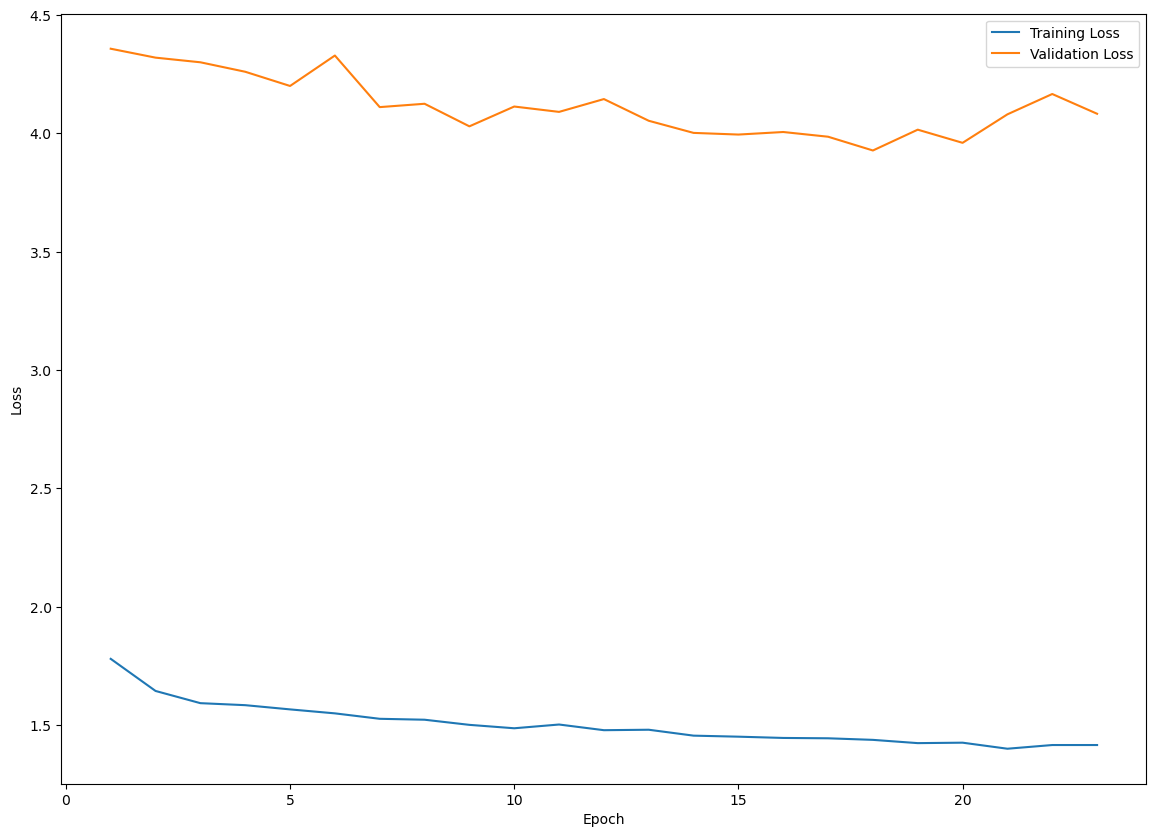

In [48]:
plt.figure(figsize=(14, 10))
epochs_range = range(1, 24)
train_loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(epochs_range, train_loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [49]:
y_pred = model.predict(X_test)
y_pred

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ 0.3133667 ],
       [ 0.20600288],
       [-0.08712645],
       ...,
       [ 0.00314979],
       [ 0.7591022 ],
       [-0.07600044]], shape=(3308, 1), dtype=float32)

In [50]:
y_pred = np.squeeze(y_pred)
y_pred

array([ 0.3133667 ,  0.20600288, -0.08712645, ...,  0.00314979,
        0.7591022 , -0.07600044], shape=(3308,), dtype=float32)

In [52]:
r2_score = r2_score(y_test, y_pred)
print("Model R2 Score: {:.4f}".format(r2_score))

Model R2 Score: 0.1370
